In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\DELL\Downloads\airline-passengers.csv")

In [3]:
df.head(2)

,month,total_passengers
0,1949-01,112
1,1949-02,118


In [4]:
df.shape

(144, 2)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   month             144 non-null    str  
 1   total_passengers  144 non-null    int64
dtypes: int64(1), str(1)
memory usage: 3.4 KB


In [6]:
df.describe()

,total_passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


In [7]:
df["month"]=pd.to_datetime(df["month"])
df=df.set_index("month")


In [8]:
df.head(3)

,total_passengers
month,
1949-01-01,112
1949-02-01,118
1949-03-01,132


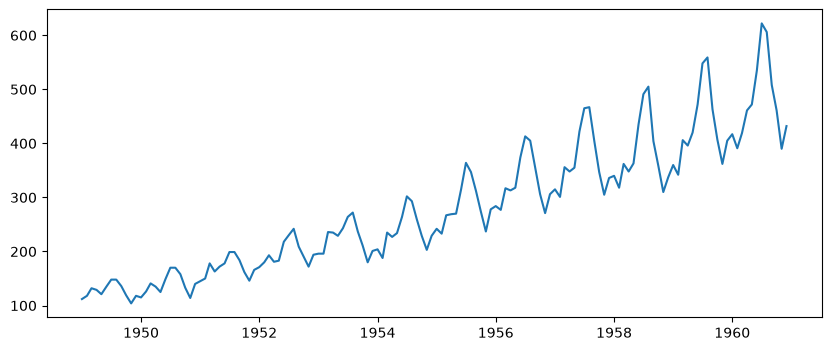

In [9]:
plt.figure(figsize=(10,4))
plt.plot(df["total_passengers"])
plt.show()


In [10]:
dates=pd.date_range(
    start="1949-01-01",
    periods=len(df),
    freq="MS"
)

In [11]:
dates

DatetimeIndex(['1949-01-01', '1949-02-01', '1949-03-01', '1949-04-01',
               '1949-05-01', '1949-06-01', '1949-07-01', '1949-08-01',
               '1949-09-01', '1949-10-01',
               ...
               '1960-03-01', '1960-04-01', '1960-05-01', '1960-06-01',
               '1960-07-01', '1960-08-01', '1960-09-01', '1960-10-01',
               '1960-11-01', '1960-12-01'],
              dtype='datetime64[us]', length=144, freq='MS')

In [12]:
ts=pd.DataFrame(
    {"passengers":df["total_passengers"]},
    index=dates
)
    

In [13]:
ts

,passengers
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1960-08-01,606
1960-09-01,508
1960-10-01,461
1960-11-01,390


In [14]:
# !pip install statsmodels

In [15]:
ts=np.log(ts)

In [16]:
ts

,passengers
1949-01-01,4.718499
1949-02-01,4.770685
1949-03-01,4.882802
1949-04-01,4.859812
1949-05-01,4.795791
...,...
1960-08-01,6.406880
1960-09-01,6.230481
1960-10-01,6.133398
1960-11-01,5.966147


In [17]:
from statsmodels.tsa.arima.model import ARIMA

In [18]:
train=ts[:-18]
test=ts[-18:]

In [19]:
arima_model=ARIMA(train,order=(1,1,12)).fit()
        

C:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [20]:
arima_model

In [21]:
arima_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:             passengers   No. Observations:                  126
Model:                ARIMA(1, 1, 12)   Log Likelihood                 157.411
Date:                Wed, 28 Oct 2026   AIC                           -286.822
Time:                        12:26:41   BIC                           -247.226
Sample:                    01-01-1949   HQIC                          -270.736
                         - 06-01-1959                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1806      0.177      1.019      0.308      -0.167       0.528
ma.L1         -0.1975      0.423     -0.467      0.640      -1.026       0.631
ma.L2         -0.0379      0.209     -0.181      0.856      -0.448       0.372
ma.L3         -0.2247      0.185     -1.216      0.224      -0.587       0.137
ma.L4         -0.1365      0.336     -0.407      0.684      -0.794       0.521
ma.L5          0.1119      0.283      0.396      0.692      -0.443       0.666
ma.L6         -0.1432      0.106     -1.350      0.177      -0.351       0.065
ma.L7          0.0981      0.251      0.391      0.696      -0.394       0.590
ma.L8         -0.3822      0.377     -1.013      0.311      -1.122       0.357
ma.L9          0.1015      0.185      0.548      0.584      -0.261       0.464
ma.L10        -0.2324      0.196     -1.183      0.237      -0.617       0.153
ma.L11         0.1100      0.312      0.353      0.724      -0.501       0.721
ma.L12         0.7442      0.262      2.837      0.005       0.230       1.258
sigma2         0.0042      0.001      2.892      0.004       0.001       0.007
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):                 4.28
Prob(Q):                              0.89   Prob(JB):                         0.12
Heteroskedasticity (H):               0.81   Skew:                             0.35
Prob(H) (two-sided):                  0.51   Kurtosis:                         2.42
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [22]:
y_pred=arima_model.forecast(steps=18)

In [23]:
y_pred

1959-07-01    6.222685
1959-08-01    6.245198
1959-09-01    6.139896
1959-10-01    6.095321
1959-11-01    6.004036
1959-12-01    5.981983
1960-01-01    5.989777
1960-02-01    5.979965
1960-03-01    6.044879
1960-04-01    6.075865
1960-05-01    6.099441
1960-06-01    6.132454
1960-07-01    6.138416
1960-08-01    6.139492
1960-09-01    6.139687
1960-10-01    6.139722
1960-11-01    6.139728
1960-12-01    6.139729
Freq: MS, Name: predicted_mean, dtype: float64

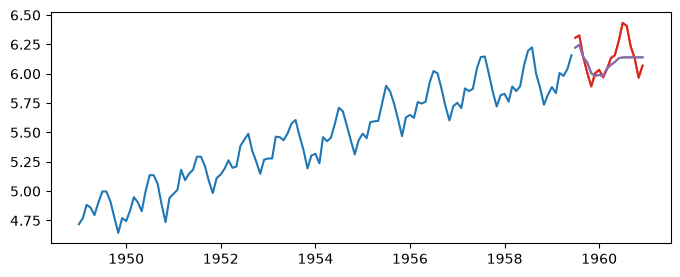

In [24]:
plt.figure(figsize=(8,3))
plt.plot(train.index,train.passengers)
plt.plot(test.index,test.passengers)
plt.plot(y_pred)
plt.plot(test)
plt.plot(y_pred)

plt.show()

In [26]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [29]:
sarima=SARIMAX(train,order=(1,1,1),seasonal_order=(1,1,1,12)).fit()

C:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [32]:
sarima.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                         passengers   No. Observations:                  126
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 210.263
Date:                            Wed, 28 Oct 2026   AIC                           -410.526
Time:                                    12:29:53   BIC                           -396.889
Sample:                                01-01-1949   HQIC                          -404.993
                                     - 06-01-1959                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2489      0.251      0.992      0.321      -0.243       0.741
ma.L1         -0.5881      0.219     -2.688      0.007      -1.017      -0.159
ar.S.L12      -0.0724      0.228     -0.317      0.751      -0.520       0.375
ma.S.L12      -0.5217      0.240     -2.169      0.030      -0.993      -0.050
sigma2         0.0014      0.000      7.308      0.000       0.001       0.002
===================================================================================
Ljung-Box (L1) (Q):                   0.05   Jarque-Bera (JB):                 2.05
Prob(Q):                              0.82   Prob(JB):                         0.36
Heteroskedasticity (H):               0.43   Skew:                             0.01
Prob(H) (two-sided):                  0.01   Kurtosis:                         3.66
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [37]:
sarima_pred=sarima.forecast(steps=18)

In [38]:
sarima_pred

1959-07-01    6.277221
1959-08-01    6.285348
1959-09-01    6.115924
1959-10-01    5.982749
1959-11-01    5.846477
1959-12-01    5.948538
1960-01-01    5.987554
1960-02-01    5.936435
1960-03-01    6.091720
1960-04-01    6.064810
1960-05-01    6.105387
1960-06-01    6.253340
1960-07-01    6.369201
1960-08-01    6.377669
1960-09-01    6.204081
1960-10-01    6.071930
1960-11-01    5.934882
1960-12-01    6.035597
Freq: MS, Name: predicted_mean, dtype: float64

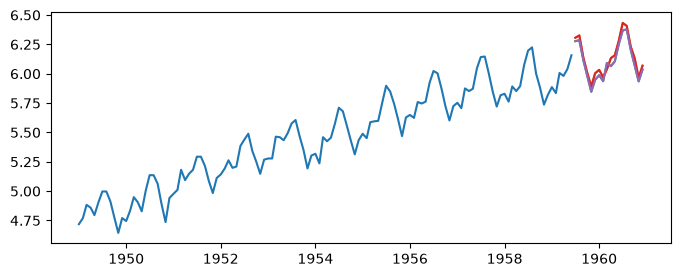

In [39]:
plt.figure(figsize=(8,3))
plt.plot(train.index,train.passengers)
plt.plot(test.index,test.passengers)
plt.plot(y_pred)
plt.plot(test)
plt.plot(y_pred)


plt.show()

In [41]:
train.index.month

Index([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10,
       ...
        9, 10, 11, 12,  1,  2,  3,  4,  5,  6],
      dtype='int32', length=126)

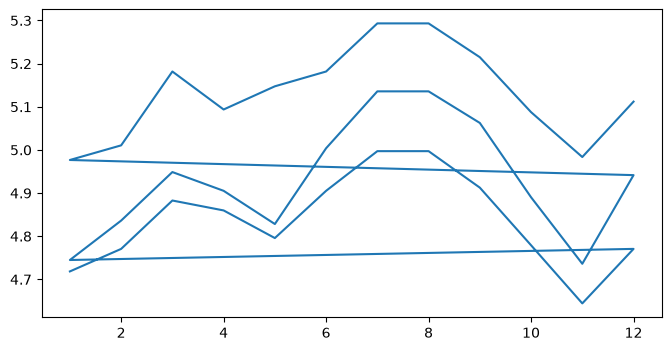

In [44]:
plt.figure(figsize=(8,4))
plt.plot(train.index.month[:36],train.passengers[:36])
plt.show()

In [45]:
train['peak_time']=train.index.month.map(lambda val: 1 if val==7 and or val==8 else 0)

SyntaxError: expected 'else' after 'if' expression (4050926430.py, line 1)